In [1]:
!pip install datasets
!pip install transformers
!pip install peft
!pip install evaluate
!pip install -U torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 60.3 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [2]:
from datasets import load_dataset, DatasetDict, Dataset

from transformers import (
    AutoTokenizer,
    AutoConfig,
    AutoModelForSequenceClassification,
    pipeline,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer)

from peft import PeftModel, PeftConfig, get_peft_model, LoraConfig
import evaluate
from evaluate import evaluator
import torch
import numpy as np
import torch

import pandas as pd #for the datasets
from sklearn.model_selection import train_test_split

import os
os.environ["WANDB_MODE"] = "disabled"

In [3]:
#dataset
df = pd.read_csv("/content/train-val-test.csv")


In [4]:
#Remove NaN (Excel always has them)
df = df.fillna("")

#Convert every object column to string
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].astype(str)

#Check for any remaining non-strings should print nothing
for col in df.columns:
    if df[col].dtype == "object":
        bad = df[~df[col].apply(lambda x: isinstance(x, str))]
        if len(bad) > 0:
            print(f"Still broken: {col}")


In [5]:
#train-test-split
df = df.rename(columns={"final_label": "labels", "sentence_gpt4": "sentence"})

grouped = df.groupby(['labels'])
grouped_data = pd.concat([grouped.get_group(x) for x in grouped.groups])

train_data, test_validation_data = train_test_split(df, test_size=0.26, random_state=10, stratify=df['labels'])
test_data, validation_data = train_test_split(test_validation_data, test_size=0.25, random_state=10, stratify=test_validation_data['labels'])

train_df = pd.DataFrame(train_data)
test_df = pd.DataFrame(test_data)
validation_df = pd.DataFrame(validation_data)

print(f"Train size: {len(train_df)}, Test size: {len(test_df)}, Validation size: {len(validation_df)}")

# Check label distribution in each split
for split_name, split_df in zip(
    ["train", "test", "validation"],
    [train_df, test_df, validation_df]
):
    print(f"\n{split_name.upper()} labels:")
    print(split_df['labels'].value_counts())


Train size: 1172, Test size: 309, Validation size: 103

TRAIN labels:
labels
0    589
1    583
Name: count, dtype: int64

TEST labels:
labels
0    155
1    154
Name: count, dtype: int64

VALIDATION labels:
labels
0    52
1    51
Name: count, dtype: int64


/tmp/ipykernel_816/3190129425.py:5: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  grouped_data = pd.concat([grouped.get_group(x) for x in grouped.groups])


In [6]:
# Convert dfs to separate Datasets
train_dataset = Dataset.from_pandas(train_df)
test_dataset = Dataset.from_pandas(test_df)
validation_dataset = Dataset.from_pandas(validation_df)

# Combine the datasets into a DatasetDict
dataset = DatasetDict({
    'train': train_dataset,
    'test': test_dataset,
    'validation': validation_dataset
})

In [7]:
# Define the label mappings
model_checkpoint = "bert-base-uncased"

model = AutoModelForSequenceClassification.from_pretrained(
    model_checkpoint,
    num_labels=2,
    ignore_mismatched_sizes=True # Add this line to ignore size mismatches
)

# display architecture classifier maps BERT’s 768-dim pooled output to logits for your 2 classes (emotion and non-emotion)
model

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [8]:
# create tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint, add_prefix_space=True)

# add pad token if none exists
if tokenizer.pad_token is None:
    tokenizer.add_special_tokens({'pad_token': '[PAD]'})
    model.resize_token_embeddings(len(tokenizer))

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [9]:
def tokenize_function(examples):
    text = examples["sentence"]  # Change this if dataset key is different
    tokenizer.truncation_side = "left"
    return tokenizer(
        examples["sentence"],
        truncation=True,
        max_length=512,
        padding="longest"  # Optional
    )

#test tokenizer function
sample_text = dataset['train'][82]["sentence"]
tokenized_example = tokenize_function({"sentence": sample_text})
print(tokenized_example)

{'input_ids': [101, 2008, 4445, 8725, 2005, 2033, 4496, 24665, 2666, 7178, 2012, 1996, 4028, 1997, 2026, 2293, 1010, 2026, 2568, 2003, 3876, 1010, 2017, 2007, 2122, 15784, 2616, 1010, 2007, 12640, 2033, 2021, 2205, 2146, 2013, 2026, 4792, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [10]:
# tokenize training and validation datasets
tokenized_dataset = dataset.map(tokenize_function, batched=True)
tokenized_dataset

Map:   0%|          | 0/1172 [00:00<?, ? examples/s]

Map:   0%|          | 0/309 [00:00<?, ? examples/s]

Map:   0%|          | 0/103 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['normalizedGenre', 'filename', 'play_title', 'speaker_id', 'speaker_name', 'speaker_spblock', 'gender', 'sentence_number', 'sample_index', 'sentence_original', 'sentence', 'rater1', 'rater2', 'rater3', 'labels', 'rating_match', '__index_level_0__', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1172
    })
    test: Dataset({
        features: ['normalizedGenre', 'filename', 'play_title', 'speaker_id', 'speaker_name', 'speaker_spblock', 'gender', 'sentence_number', 'sample_index', 'sentence_original', 'sentence', 'rater1', 'rater2', 'rater3', 'labels', 'rating_match', '__index_level_0__', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 309
    })
    validation: Dataset({
        features: ['normalizedGenre', 'filename', 'play_title', 'speaker_id', 'speaker_name', 'speaker_spblock', 'gender', 'sentence_number', 'sample_index', 'sentence_original', 'sentence', 'rater1', 'rater2', 'rater3', 'la

In [11]:
#finetuning process settings
peft_config = LoraConfig(task_type="SEQ_CLS",
                        r=4,
                        lora_alpha=32,
                        lora_dropout=0.01,
                        target_modules = ['query'])

#peft_config
model = get_peft_model(model, peft_config)
model.print_trainable_parameters()

# training configuration, hyperparameters
lr = 1e-3
batch_size = 4
num_epochs = 5

# define training arguments
training_args = TrainingArguments(
    output_dir= model_checkpoint + "imex",
    learning_rate=lr,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    num_train_epochs=num_epochs,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
)

trainable params: 75,266 || all params: 109,559,044 || trainable%: 0.0687


In [12]:
#training bar shows number of training stages NOT number of examples in dataset

#import evaluation metric for accuracy
from sklearn.metrics import precision_recall_fscore_support, accuracy_score # Import necessary functions

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = logits.argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, predictions, average="binary")
    accuracy = accuracy_score(labels, predictions)
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}

# creater trainer object
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    #data_collator=data_collator,
    compute_metrics=compute_metrics,
)

# train model
trainer.train()

[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,No log,0.450479,0.834951,0.765625,0.960784,0.852174
2,0.471248,0.232468,0.941748,0.959184,0.921569,0.940000
3,0.471248,0.345924,0.932039,0.907407,0.960784,0.933333
4,0.209238,0.317578,0.951456,0.979167,0.921569,0.949495
5,0.209238,0.278818,0.951456,0.979167,0.921569,0.949495


TrainOutput(global_step=1465, training_loss=0.2753419791472243, metrics={'train_runtime': 189.3566, 'train_samples_per_second': 30.947, 'train_steps_per_second': 7.737, 'total_flos': 645003405119040.0, 'train_loss': 0.2753419791472243, 'epoch': 5.0})

In [13]:
#save to hub
from huggingface_hub import notebook_login
notebook_login()

In [14]:
model.push_to_hub("descbert")
tokenizer.push_to_hub("descbert")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors: 100%|##########|  305kB /  305kB            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

CommitInfo(commit_url='https://huggingface.co/e0572777/descbert/commit/ca3776fde6b22d3483cd5da9ec6831878129b097', commit_message='Upload tokenizer', commit_description='', oid='ca3776fde6b22d3483cd5da9ec6831878129b097', pr_url=None, repo_url=RepoUrl('https://huggingface.co/e0572777/descbert', endpoint='https://huggingface.co', repo_type='model', repo_id='e0572777/descbert'), pr_revision=None, pr_num=None)

evaluate bert model

In [15]:
# Load pre-trained model and tokenizer
from peft import PeftModel, PeftConfig
from transformers import AutoModelForSequenceClassification, AutoTokenizer, pipeline

model_name = "e0572777/descbert"

# Load the PEFT config to find the base model
peft_config = PeftConfig.from_pretrained(model_name)

# Load base model
base_model = AutoModelForSequenceClassification.from_pretrained(
    peft_config.base_model_name_or_path,
    num_labels=2
)

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(peft_config.base_model_name_or_path)

# Load the LoRA adapter on top
model = PeftModel.from_pretrained(base_model, model_name)
model = model.merge_and_unload()  # merges LoRA weights into the base model

model.eval()  # add this

classifier = pipeline("text-classification", model=model, tokenizer=tokenizer, batch_size=32)

adapter_config.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


adapter_model.safetensors: reconstructing file:   0%|          |  0.00B /  305kB            

adapter_model.safetensors: downloading bytes:           |  0.00B            

In [16]:
def predict_batch(model, tokenizer, prepared_data, batch_size=32):
    all_preds = []
    keys = tokenizer.model_input_names
    dataset_length = len(prepared_data[keys[0]])

    for i in range(0, dataset_length, batch_size):
        batch = {key: prepared_data[key][i:i + batch_size] for key in keys}
        # No changes to tensor conversion, padding handled in preprocessing
        inputs = {key: torch.tensor(val).to(model.device) for key, val in batch.items()}
        with torch.no_grad():
            outputs = model(**inputs)

        logits = outputs.logits
        preds = torch.argmax(logits, dim=-1)
        all_preds.extend(preds.cpu().tolist())

    return all_preds

# Prepare data for batching
def prepare_batch(encoded_dataset):
    keys = tokenizer.model_input_names
    return {key: encoded_dataset[key] for key in keys}

eval_dataset=tokenized_dataset["test"]
prepared_data = prepare_batch(eval_dataset)

# Predict in batches
batch_size = 32
predicted_labels = predict_batch(model, tokenizer, prepared_data, batch_size=batch_size)

In [17]:
#save test set predicted labels
df = pd.DataFrame(eval_dataset)
df["predicted_label"] = predicted_labels

# Add mismatch analysis column
def classify_mismatch(row):
    if row["labels"] == row["predicted_label"]:
        return "correct"
    elif row["labels"] == 1 and row["predicted_label"] == 0:
        return "false_negative"
    elif row["labels"] == 0 and row["predicted_label"] == 1:
        return "false_positive"

df["result"] = df.apply(classify_mismatch, axis=1)

print(df.head())
print("\nResult counts:")
print(df["result"].value_counts())

df.to_excel("/content/descbert_eval.xlsx", index=False)

  normalizedGenre                                  filename  \
0          Comedy                      mayne-the-city-match   
1          Comedy                 dekker-match-me-in-london   
2         Tragedy                           chettle-hoffman   
3          Comedy  beaumont-fletcher-massinger-beggars-bush   
4     Tragicomedy                  brome-the-lovesick-court   

                                     play_title         speaker_id  \
0                                The City Match  eng000156-aurelia   
1                            Match Me in London     eng000317-king   
2            Hoffman, or A Revenge for a Father  eng000286-sarlois   
3                                 Beggars' Bush   eng000335-gerard   
4  The Lovesick Court, or The Ambitious Politic  eng000422-thymele   

  speaker_name speaker_spblock  gender  sentence_number  sample_index  \
0      Aurelia            Aur.  Female              995             8   
1         King           King.    Male              17

Accuracy : 0.9223
Precision: 0.9333
Recall   : 0.9091
F1-score : 0.9211

Detailed report:
              precision    recall  f1-score   support

 non-emotion       0.91      0.94      0.92       155
     emotion       0.93      0.91      0.92       154

    accuracy                           0.92       309
   macro avg       0.92      0.92      0.92       309
weighted avg       0.92      0.92      0.92       309



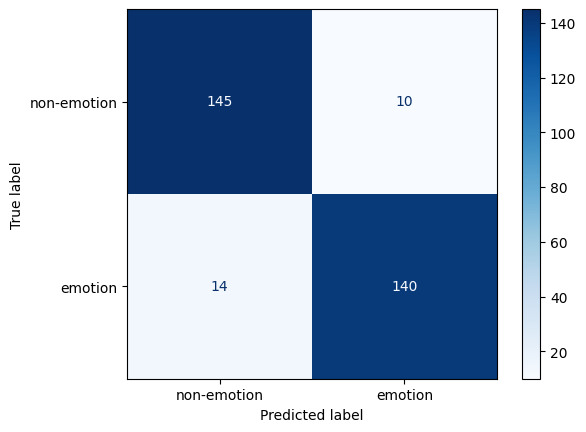

In [18]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

# Map true_labels to labels
label_map = {0: "non-emotion", 1: "emotion"}  # Update based on your model
true_labels = [label for label in eval_dataset["labels"]]
#true_labels = [label_map[label] for label in encoded_dataset["label"]]


# Map predicted and true labels to integers
y_pred = predicted_labels
y_true = true_labels

accuracy = accuracy_score(y_true, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="binary"
)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nDetailed report:")
print(classification_report(y_true, y_pred, target_names=["non-emotion", "emotion"]))

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Compute confusion matrix
cm = confusion_matrix(true_labels, predicted_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["non-emotion", "emotion"])
disp.plot(cmap="Blues")
plt.show()